# Mean ISOP and MTERP emissions: vegetation × climate (interaction plot)
Condensed version of `plot_bvoc_timeseries.ipynb`: each yearly time series becomes **one mean value with an error bar**, all in one plot per species.

**Figure 1:** ISOP and MTERP (`SF*`). **Figure 2 (section 4):** the other 17 MEGAN species CAM receives (`MEG_*`).

- **x axis = vegetation:** `VEG_CTRL` = CTRL land cover, `VEG_LCC` = LCC land cover (forest expansion).
- **Lines = climate:** **navy** = PD climate (CTRL_PD → LCC_PD), **red** = FUT climate (CTRL_FUT → LCC_FUT).
- **PD → FUT** (navy → red gradient): full change, vegetation + climate together (CTRL_PD → LCC_FUT). It ends on the LCC_FUT point of the FUT line (same run, same value).
- Arrows point from CTRL to LCC land cover (PD → FUT: from CTRL_PD to LCC_FUT); the runs are written along each arrow, colours in the legend.
- Parallel PD and FUT lines = no interaction; a steeper FUT line = the forest effect on emissions grows in the warmer climate.
- **Values:** mean of the yearly totals over the analysis years; **error bars = ±1 interannual standard deviation** of the yearly totals.
- Emissions **received by the atmosphere** (`SFISOP`, `SFMTERP`, CAM h0, MEGAN + biomass burning), Tg(species)/yr, area-integrated over the LCC-modified cells (1161 cells, 46–82°N, `diagnostics/lcc-modified-cells/modified_cells.nc`).
- **Input:** `data/processed-data/postprocessing/<ALIAS>_atm_BVOC_<START>-<END>.nc` (interactive runs only; the fBVOC runs are prescribed, so their emissions are a copy of their source run).


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib.legend_handler import HandlerLineCollection
from matplotlib.colors import LinearSegmentedColormap
from IPython.display import display

REPO = Path("/cluster/home/adelez/BOREAL-FOREST-EXPANSION")
PROC = REPO / "data/processed-data/postprocessing"
MASK_FILE = REPO / "diagnostics/lcc-modified-cells/modified_cells.nc"
START, END = 2001, 2025          # 2001-2014 files also exist; set END = 2014 to match plot_bvoc_timeseries
SPECIES = {"SFISOP": "ISOP", "SFMTERP": "MTERP"}
OUTDIR = REPO / "diagnostics/2_bvoc-emissions/plot_bvoc_means_outputs"
OUTDIR.mkdir(exist_ok=True)
NAVY, RED = "#2C3990", "#BC423E"   # project palette: PD navy, FUT red
# (climate, vegetation) -> run
RUNS = {("PD", "VEG_CTRL"): "CTRL_PD", ("PD", "VEG_LCC"): "LCC_PD",
        ("FUT", "VEG_CTRL"): "CTRL_FUT", ("FUT", "VEG_LCC"): "LCC_FUT"}


## 1. Yearly totals per run
Same method as `plot_bvoc_timeseries.ipynb`: monthly flux (kg m⁻² s⁻¹) × cell area × seconds in the month (noleap), summed over each complete calendar year. Cell areas from `gw`, scaled so the globe = 4πR². The grid of every run is checked against the mask grid.

In [2]:
with xr.open_dataset(MASK_FILE) as ds:
    mask = ds["modified"].load().astype(bool)
R = 6.371e6

def masked_area(ds, alias):
    """Cell area (m²) on the LCC-modified cells, 0 elsewhere; checks the model grid against the mask grid."""
    for name, a, b in (("lat", mask.lat.values, ds.lat.values), ("lon", mask.lon.values % 360, ds.lon.values % 360)):
        if a.shape != b.shape or np.abs(a - b).max() > 1e-5:
            raise ValueError(f"{alias}: mask and model {name} differ")
    gw = ds["gw"].isel(time=0) if "time" in ds["gw"].dims else ds["gw"]
    area = (gw / float(gw.sum()) / ds.sizes["lon"] * 4 * np.pi * R**2) * xr.ones_like(ds.lon)
    return area.where(mask.assign_coords(lat=ds.lat, lon=ds.lon), 0)

def yearly_totals(alias):
    path = PROC / f"{alias}_atm_BVOC_{START}-{END}.nc"
    with xr.open_dataset(path) as ds:
        bounds = ds["time_bnds"].values
        t0 = np.array([b[0] for b in bounds]); t1 = np.array([b[1] for b in bounds])
        if type(t0[0]).__name__ != "DatetimeNoLeap":
            raise ValueError(f"{alias}: calendar {type(t0[0]).__name__}, expected noleap")
        days = np.array([(b - a).days for a, b in zip(t0, t1)], float)
        ds = ds.assign_coords(year=("time", np.array([a.year for a in t0])), days=("time", days))
        w = masked_area(ds, alias)
        rows = []
        for s, sp in SPECIES.items():
            if ds[s].attrs.get("units") != "kg/m2/s":
                raise ValueError(f"{alias} {s}: units {ds[s].attrs.get('units')}")
            monthly = (ds[s] * ds["days"] * 86400 * w).sum(("lat", "lon")).load()
            g = monthly.groupby("year")
            n, tot = g.count().to_series(), g.sum().to_series() / 1e9          # Tg/yr
            full = n.index[(n == 12) & (n.index >= START) & (n.index <= END)]
            rows.append(pd.DataFrame({"alias": alias, "species": sp, "year": full, "Tg_per_yr": tot.loc[full].values}))
    out = pd.concat(rows)
    print(f"{alias:10s} {out.year.min()}–{out.year.max()} ({out.year.nunique()} yr)  from {path.name}")
    return out

annual = pd.concat([yearly_totals(a) for a in RUNS.values()], ignore_index=True)


CTRL_PD    2001–2025 (25 yr)  from CTRL_PD_atm_BVOC_2001-2025.nc


LCC_PD     2001–2025 (25 yr)  from LCC_PD_atm_BVOC_2001-2025.nc


CTRL_FUT   2001–2025 (25 yr)  from CTRL_FUT_atm_BVOC_2001-2025.nc


LCC_FUT    2001–2025 (25 yr)  from LCC_FUT_atm_BVOC_2001-2025.nc


## 2. Means and interannual spread (Tg/yr)
Mean and ±1 standard deviation (ddof = 1) of the yearly totals. Below: the effects read off the plot (Δ = mean difference, % of the first run's mean).

In [3]:
stats = annual.groupby(["species", "alias"]).Tg_per_yr.agg(["mean", "std", "count"])
with pd.option_context("display.float_format", "{:.4g}".format):
    display(stats.unstack("species"))

EFFECTS = {"Forest effect, PD climate (LCC_PD − CTRL_PD)": ("LCC_PD", "CTRL_PD"),
           "Forest effect, FUT climate (LCC_FUT − CTRL_FUT)": ("LCC_FUT", "CTRL_FUT"),
           "Climate effect, PD veg. (CTRL_FUT − CTRL_PD)": ("CTRL_FUT", "CTRL_PD"),
           "Climate effect, FUT veg. (LCC_FUT − LCC_PD)": ("LCC_FUT", "LCC_PD"),
           "PD → FUT, both (LCC_FUT − CTRL_PD)": ("LCC_FUT", "CTRL_PD")}
rows = []
for sp in SPECIES.values():
    m = stats.loc[sp, "mean"]
    for name, (a, b) in EFFECTS.items():
        rows.append({"species": sp, "effect": name, "delta_Tg_per_yr": m[a] - m[b], "pct": 100 * (m[a] - m[b]) / m[b]})
    inter = (m["LCC_FUT"] - m["CTRL_FUT"]) - (m["LCC_PD"] - m["CTRL_PD"])
    rows.append({"species": sp, "effect": "Interaction (FUT forest effect − PD forest effect)", "delta_Tg_per_yr": inter, "pct": np.nan})
effects = pd.DataFrame(rows)
with pd.option_context("display.float_format", "{:+.3g}".format, "display.max_colwidth", 60):
    display(effects.pivot(index="effect", columns="species", values=["delta_Tg_per_yr", "pct"]).loc[list(EFFECTS) + ["Interaction (FUT forest effect − PD forest effect)"]])


mean          std        count      
species   ISOP MTERP   ISOP  MTERP  ISOP MTERP
alias                                         
CTRL_FUT 12.57 22.75 0.8029 0.9427    25    25
CTRL_PD  4.086 4.938 0.3362 0.2333    25    25
LCC_FUT  12.91 22.61 0.8308 0.9057    25    25
LCC_PD    4.33 4.967 0.3572 0.2316    25    25

delta_Tg_per_yr          \
species                                                       ISOP   MTERP   
effect                                                                       
Forest effect, PD climate (LCC_PD − CTRL_PD)                +0.244 +0.0296   
Forest effect, FUT climate (LCC_FUT − CTRL_FUT)             +0.346  -0.139   
Climate effect, PD veg. (CTRL_FUT − CTRL_PD)                 +8.48   +17.8   
Climate effect, FUT veg. (LCC_FUT − LCC_PD)                  +8.58   +17.6   
PD → FUT, both (LCC_FUT − CTRL_PD)                           +8.83   +17.7   
Interaction (FUT forest effect − PD forest effect)          +0.102  -0.169   

                                                     pct         
species                                             ISOP  MTERP  
effect                                                           
Forest effect, PD climate (LCC_PD − CTRL_PD)       +5.97   +0.6  
Forest effect, FUT climate (LCC_FUT − CTRL_FUT)    +2.75 -0.612  
Climate effect, PD veg. (CTRL_FUT − CTRL_PD)        +208   +361  
Climate effect, FUT veg. (LCC_FUT − LCC_PD)         +198   +355  
PD → FUT, both (LCC_FUT − CTRL_PD)                  +216   +358  
Interaction (FUT forest effect − PD forest effect)   NaN    NaN

## 3. Interaction plot, one panel per species
Each panel has its own y scale starting at 0 (ISOP and MTERP differ by about an order of magnitude). PNG (200 dpi) saved in `plot_bvoc_means_outputs/`.

Saved diagnostics/2_bvoc-emissions/plot_bvoc_means_outputs/bvoc_means_veg_x_climate_modified_2001-2025.png


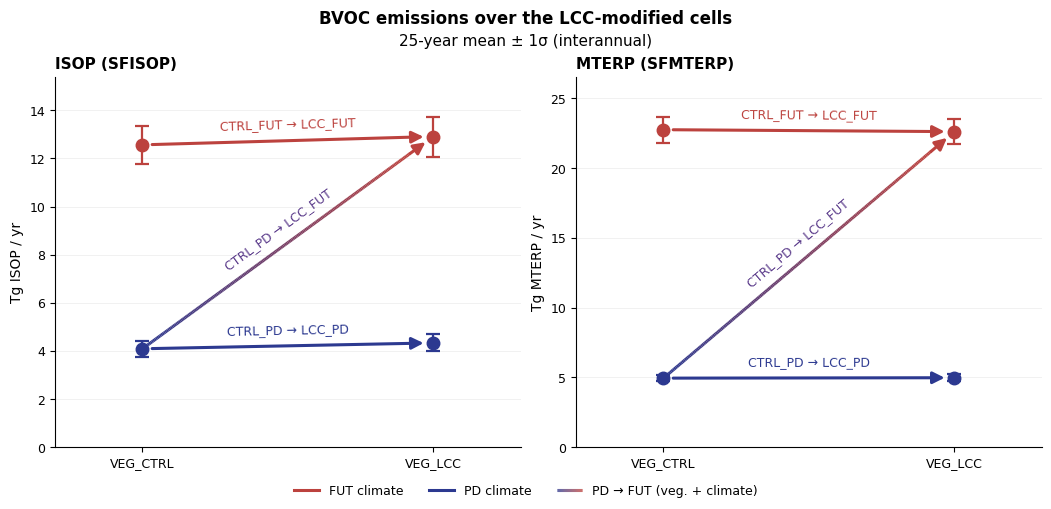

In [4]:
X = {"VEG_CTRL": 0.0, "VEG_LCC": 1.0}
CMAP = LinearSegmentedColormap.from_list("pd_fut", [NAVY, RED])
style = dict(fmt="o", ms=9, capsize=5, capthick=1.6, elinewidth=1.6, zorder=3)
LW, SHRINK = 2.2, 7                     # arrow line width; gap (points) between arrow tip and marker centre
ARROW = dict(arrowstyle="-|>,head_length=0.7,head_width=0.35", lw=LW, shrinkA=SHRINK, shrinkB=SHRINK)

def gradient_line(ax, x0, y0, x1, y1, n=200, **kw):
    xs, ys = np.linspace(x0, x1, n), np.linspace(y0, y1, n)
    seg = np.stack([np.column_stack([xs[:-1], ys[:-1]]), np.column_stack([xs[1:], ys[1:]])], axis=1)
    ax.add_collection(LineCollection(seg, cmap=CMAP, array=np.linspace(0, 1, n - 1), lw=LW, capstyle="butt", **kw))

def gradient_arrow(ax, p0, p1):
    """navy -> red line from p0 to 92 % of the way, then a red arrow head ending at the p1 marker."""
    pm = (p0[0] + 0.92 * (p1[0] - p0[0]), p0[1] + 0.92 * (p1[1] - p0[1]))
    gradient_line(ax, *p0, *pm, zorder=2)
    ax.annotate("", p1, pm, arrowprops=dict(ARROW, color=RED, shrinkA=0), zorder=2)

class HandlerGradient(HandlerLineCollection):
    """Legend key for the PD → FUT arrow: navy → red gradient."""
    def create_artists(self, legend, orig, xd, yd, width, height, fontsize, trans):
        x = np.linspace(-xd, width - xd, 30); y = np.full_like(x, height / 2 - yd)
        seg = np.stack([np.column_stack([x[:-1], y[:-1]]), np.column_stack([x[1:], y[1:]])], axis=1)
        return [LineCollection(seg, cmap=CMAP, array=np.linspace(0, 1, len(x) - 1), lw=LW, transform=trans)]

def label_on_line(ax, p0, p1, text, color, frac=0.5, offset=7, fontsize=9):
    """Text along the segment p0 -> p1 (screen angle), shifted `offset` points to its left/upper side."""
    xy = (p0[0] + frac * (p1[0] - p0[0]), p0[1] + frac * (p1[1] - p0[1]))
    (a0, b0), (a1, b1) = ax.transData.transform([p0, p1])
    ang = np.degrees(np.arctan2(b1 - b0, a1 - a0))
    off = offset * np.array([-np.sin(np.radians(ang)), np.cos(np.radians(ang))])
    ax.annotate(text, xy, xytext=off, textcoords="offset points", rotation=ang, rotation_mode="anchor",
                ha="center", va="bottom" if offset > 0 else "top", fontsize=fontsize, color=color)

def interaction_figure(stats, species, titles, units, ncols, panel_w, panel_h, label_fs, suptitle, nyr, path):
    """One interaction panel per species (x = vegetation, lines = climate). stats: mean/std indexed by (species, alias)."""
    nrows = int(np.ceil(len(species) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(panel_w * ncols, panel_h * nrows), constrained_layout=True, squeeze=False)
    axes = axes.ravel()
    for ax in axes[len(species):]:
        ax.set_visible(False)
    axes = axes[:len(species)]
    for ax, sp in zip(axes, species):
        m, s = stats.loc[sp, "mean"], stats.loc[sp, "std"]
        for clim, color in (("FUT", RED), ("PD", NAVY)):
            ys, es = zip(*((m[RUNS[clim, v]], s[RUNS[clim, v]]) for v in X))
            ax.errorbar(list(X.values()), ys, yerr=es, color=color, **style)
            ax.plot([], [], color=color, lw=LW, label=f"{clim} climate")          # legend key
        ax.set_xticks(list(X.values()), list(X.keys()), fontsize=10 if label_fs >= 9 else 8)
        ax.set_xlim(-0.3, 1.3)
        ax.set_ylim(0, 1.12 * (m + s).max())
        ax.set_ylabel(units(sp), fontsize=10 if label_fs >= 9 else 8)
        ax.set_title(titles[sp], fontsize=11 if label_fs >= 9 else 9, fontweight="bold", loc="left")
        ax.spines[["top", "right"]].set_visible(False)
        ax.grid(axis="y", alpha=0.25, lw=0.5)
        ax.tick_params(labelsize=9 if label_fs >= 9 else 7.5)

    handles, labels = axes[0].get_legend_handles_labels()
    handles.append(LineCollection([np.array([[0, 0], [1, 0]])])); labels.append("PD → FUT (veg. + climate)")
    fig.legend(handles, labels, handler_map={LineCollection: HandlerGradient()}, loc="outside lower center",
               ncol=3, frameon=False, fontsize=9 if label_fs >= 9 else 10)
    title = fig.suptitle(suptitle + "\n", fontsize=12 if label_fs >= 9 else 14, fontweight="bold")
    fig.canvas.draw()                       # fix the layout before computing on-screen angles

    for ax, sp in zip(axes, species):
        m = stats.loc[sp, "mean"]
        p = lambda clim, veg: (X[veg], m[RUNS[clim, veg]])
        for clim, color in (("FUT", RED), ("PD", NAVY)):
            a, b = p(clim, "VEG_CTRL"), p(clim, "VEG_LCC")
            ax.annotate("", b, a, arrowprops=dict(ARROW, color=color), zorder=2)
            label_on_line(ax, a, b, f"{RUNS[clim, 'VEG_CTRL']} → {RUNS[clim, 'VEG_LCC']}", color, fontsize=label_fs)
        a, b = p("PD", "VEG_CTRL"), p("FUT", "VEG_LCC")
        gradient_arrow(ax, a, b)
        label_on_line(ax, a, b, "CTRL_PD → LCC_FUT", "#5A3A8A", frac=0.5, fontsize=label_fs)

    bb = title.get_window_extent().transformed(fig.transFigure.inverted())
    fig.text(0.5, bb.y0, f"{nyr}-year mean ± 1σ (interannual)", ha="center", va="bottom", fontsize=11 if label_fs >= 9 else 12)
    fig.savefig(path, dpi=200, bbox_inches="tight")
    print("Saved", path.relative_to(REPO))
    plt.show(); plt.close(fig)

interaction_figure(stats, list(SPECIES.values()), {sp: f"{sp} (SF{sp})" for sp in SPECIES.values()},
                   lambda sp: f"Tg {sp} / yr", ncols=len(SPECIES), panel_w=5.2, panel_h=5.0, label_fs=9,
                   suptitle="BVOC emissions over the LCC-modified cells", nyr=annual.year.nunique(),
                   path=OUTDIR / f"bvoc_means_veg_x_climate_modified_{START}-{END}.png")


## 4. The other 17 MEGAN species (figure 2)
The 17 MEGAN-fed species besides ISOP and MTERP (the 19 species the fBVOC runs prescribe), as CAM receives them from the land model: **`MEG_<species>`, CAM h0, biogenic (MEGAN) only**. Their `SF*` totals are not in h0 for most species and would also contain anthropogenic and biomass-burning emissions.

- **Input:** raw CAM h0 of the four interactive runs in the work archive (`/cluster/work/users/adelez/archive/<case>/atm/hist/`; case = `casename` attribute of the postprocessed BVOC file). Same method as section 1 (noleap month lengths, same mask and cell areas).
- The yearly totals are cached in `plot_bvoc_means_outputs/bvoc_other_yearly_totals_<START>-<END>.csv` (the work archive is purged after 42 days); set `REREAD = True` to read the raw files again.
- **Units:** Gg/yr (several species are < 0.01 Tg/yr over the modified cells). Panels sorted by CTRL_PD emission, largest first.


In [5]:
RAW = Path("/cluster/work/users/adelez/archive")
OTHER = {"BCARY": "β-caryophyllene", "C3H6": "propene", "BIGENE": "alkenes ≥C4", "CH3CHO": "acetaldehyde",
         "CH2O": "formaldehyde", "C2H4": "ethene", "CH3OH": "methanol", "C2H5OH": "ethanol",
         "CH3COOH": "acetic acid", "CH3COCH3": "acetone", "HCOOH": "formic acid", "HCN": "hydrogen cyanide",
         "CO": "carbon monoxide", "C2H6": "ethane", "C3H8": "propane", "BIGALK": "alkanes ≥C4", "TOLUENE": "toluene"}
CACHE = OUTDIR / f"bvoc_other_yearly_totals_{START}-{END}.csv"
REREAD = False

def casename(alias):
    with xr.open_dataset(PROC / f"{alias}_atm_BVOC_{START}-{END}.nc") as ds:
        return ds.attrs["casename"]

def yearly_totals_meg(alias):
    case = casename(alias)
    files = sorted((RAW / case / "atm/hist").glob(f"{case}.cam.h0.*.nc"))
    files = [f for f in files if START <= int(f.name.split(".")[-2][:4]) <= END]
    w, recs = None, []
    for f in files:
        with xr.open_dataset(f) as ds:
            t0, t1 = ds["time_bnds"].values[0]
            if type(t0).__name__ != "DatetimeNoLeap":
                raise ValueError(f"{f.name}: calendar {type(t0).__name__}, expected noleap")
            if w is None:
                w = masked_area(ds, alias)
            sec = (t1 - t0).days * 86400
            rec = {"year": t0.year}
            for sp in OTHER:
                v = ds[f"MEG_{sp}"]
                if v.attrs.get("units") != "kg/m2/sec":
                    raise ValueError(f"{alias} MEG_{sp}: units {v.attrs.get('units')}")
                rec[sp] = float((v.isel(time=0) * w).sum()) * sec / 1e6       # Gg in this month
            recs.append(rec)
    monthly = pd.DataFrame(recs)
    n = monthly.groupby("year").size()
    full = n.index[n == 12]
    out = (monthly[monthly.year.isin(full)].groupby("year")[list(OTHER)].sum()
           .reset_index().melt(id_vars="year", var_name="species", value_name="Gg_per_yr"))
    out.insert(0, "alias", alias)
    print(f"{alias:10s} {out.year.min()}–{out.year.max()} ({out.year.nunique()} yr)  from {case} ({len(files)} h0 files)")
    return out

if CACHE.exists() and not REREAD:
    annual_other = pd.read_csv(CACHE)
    print("Read cached yearly totals:", CACHE.relative_to(REPO))
else:
    annual_other = pd.concat([yearly_totals_meg(a) for a in RUNS.values()], ignore_index=True)
    annual_other.to_csv(CACHE, index=False)
    print("Saved", CACHE.relative_to(REPO))

stats_other = annual_other.groupby(["species", "alias"]).Gg_per_yr.agg(["mean", "std", "count"])
order = stats_other.xs("CTRL_PD", level="alias")["mean"].sort_values(ascending=False).index.tolist()
m = stats_other["mean"].unstack("alias")[list(RUNS.values())].loc[order]
summary = m.assign(**{"forest PD %": 100 * (m.LCC_PD / m.CTRL_PD - 1), "forest FUT %": 100 * (m.LCC_FUT / m.CTRL_FUT - 1),
                      "climate (CTRL) %": 100 * (m.CTRL_FUT / m.CTRL_PD - 1), "PD → FUT %": 100 * (m.LCC_FUT / m.CTRL_PD - 1)})
with pd.option_context("display.float_format", "{:.3g}".format):
    display(summary)


CTRL_PD    2001–2025 (25 yr)  from NF2000norbc_tropstratchem_nudg_ctrl_f19_f19-20261029 (300 h0 files)


LCC_PD     2001–2025 (25 yr)  from NF2000norbc_tropstratchem_nudg_lcc_f19_f19-20261028 (300 h0 files)


CTRL_FUT   2001–2025 (25 yr)  from NF2100ssp585norbc_tropstratchem_nudg_ctrl_f19_f19-20261028 (300 h0 files)


LCC_FUT    2001–2025 (25 yr)  from NF2100ssp585norbc_tropstratchem_nudg_lcc_f19_f19-20261028 (300 h0 files)
Saved diagnostics/2_bvoc-emissions/plot_bvoc_means_outputs/bvoc_other_yearly_totals_2001-2025.csv


alias,CTRL_PD,LCC_PD,CTRL_FUT,LCC_FUT,forest PD %,forest FUT %,climate (CTRL) %,PD → FUT %
species,,,,,,,,
CH3OH,3.66e+03,3.59e+03,1.78e+04,1.7e+04,-1.92,-4.84,387,364
CO,1.45e+03,1.39e+03,8.23e+03,7.59e+03,-4.11,-7.69,468,425
CH3COCH3,1.39e+03,1.38e+03,6.27e+03,6.1e+03,-0.625,-2.72,351,339
C2H4,550,526,3.04e+03,2.81e+03,-4.34,-7.68,453,410
C3H6,495,472,2.21e+03,2.03e+03,-4.63,-7.78,345,311
CH3CHO,381,385,2.38e+03,2.36e+03,1,-0.717,525,520
C2H5OH,381,385,2.38e+03,2.36e+03,1,-0.717,525,520
BCARY,288,284,2.08e+03,2.02e+03,-1.53,-2.87,621,600
BIGENE,248,236,1.1e+03,1.02e+03,-4.63,-7.78,345,311


Saved diagnostics/2_bvoc-emissions/plot_bvoc_means_outputs/bvoc_other_means_veg_x_climate_modified_2001-2025.png


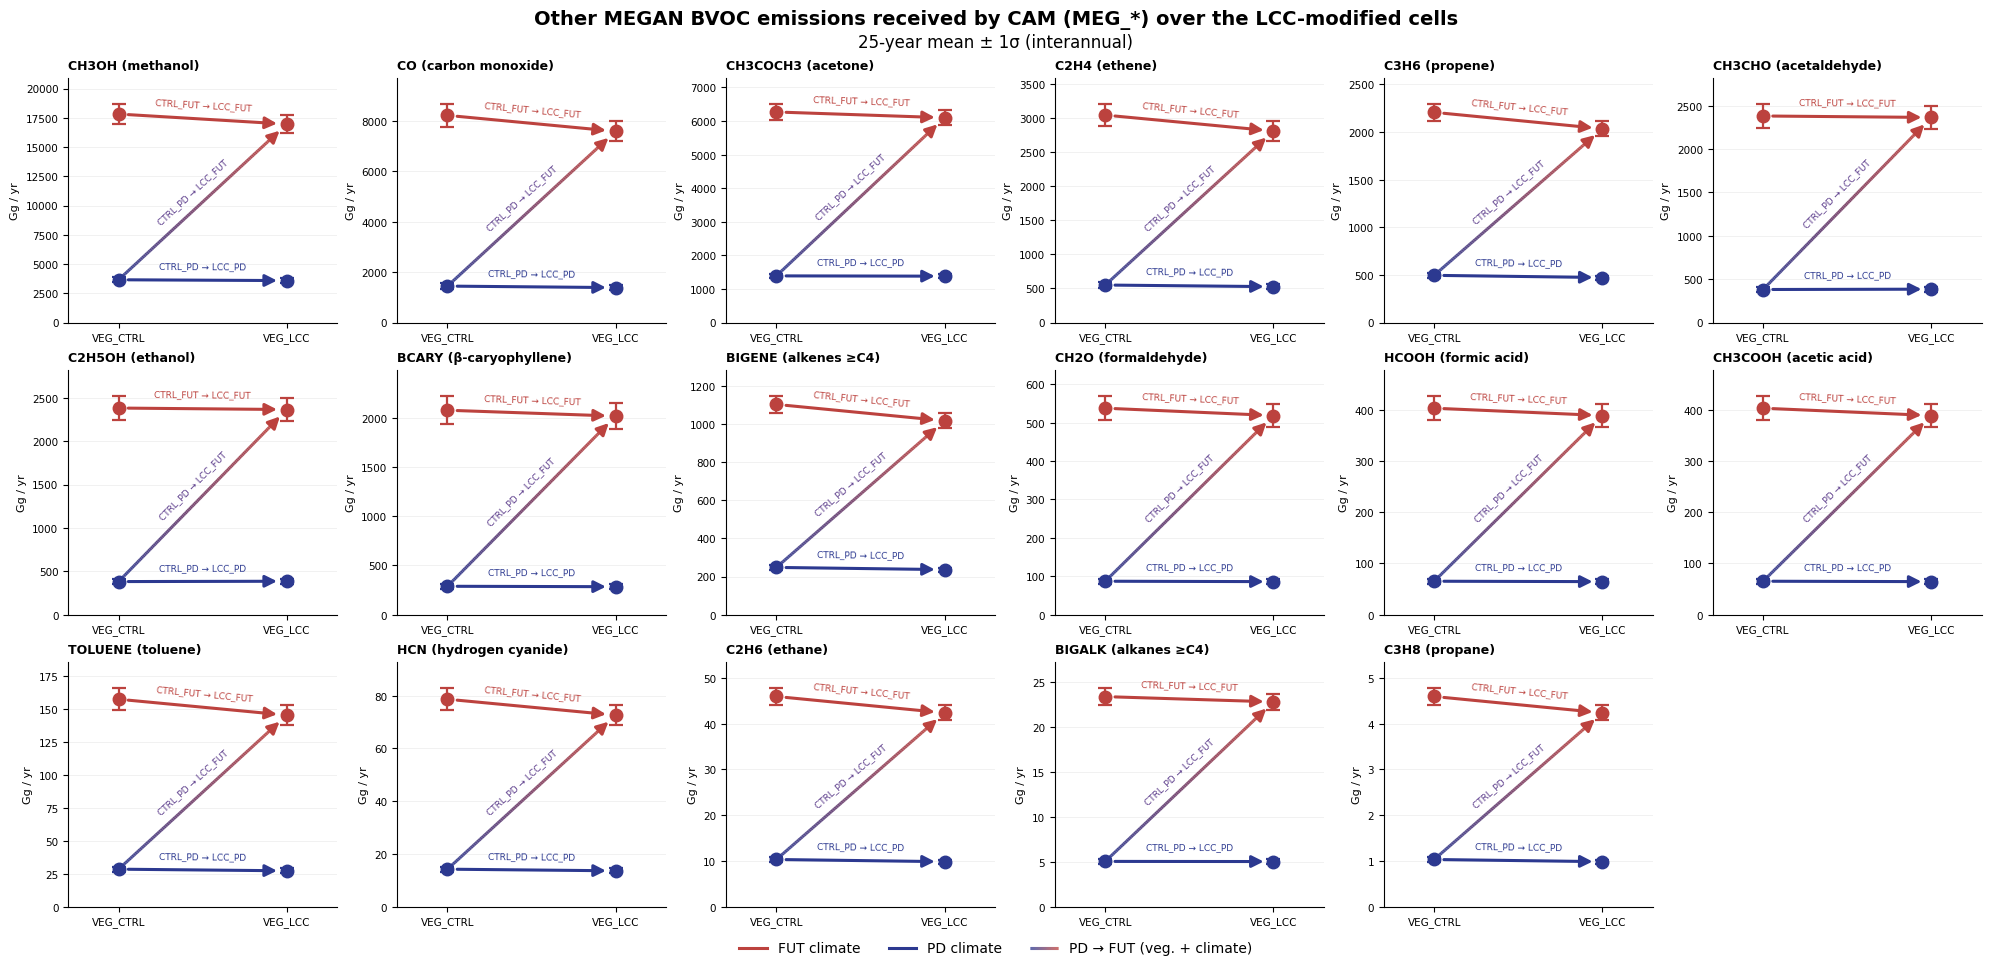

In [6]:
interaction_figure(stats_other, order, {sp: f"{sp} ({OTHER[sp]})" for sp in order},
                   lambda sp: "Gg / yr", ncols=6, panel_w=3.3, panel_h=3.2, label_fs=6.5,
                   suptitle="Other MEGAN BVOC emissions received by CAM (MEG_*) over the LCC-modified cells",
                   nyr=annual_other.year.nunique(),
                   path=OUTDIR / f"bvoc_other_means_veg_x_climate_modified_{START}-{END}.png")
